# C04-KM — K-Means (RFM + AOV + Diversity + QtyPerOrder + Tenure → log1p mọi biến → StandardScaler → PCA 90%)

Thí nghiệm **C04-KM** (người chạy: Thuận, hạn nội bộ 18/11/2026) theo chiến lược model. So với C01 (RFM + AOV + Diversity), **thêm cả QtyPerOrder và Tenure**, để đối chiếu C02, C03 và xem tương tác giữa hai biến. Quy trình: làm sạch → feature cấp khách → RFM + AOV + Diversity + QtyPerOrder + Tenure → log1p mọi biến → StandardScaler → PCA 90% → K-Means. Đây là nhóm C; C02, C03, C04 so với C01 (RFM + AOV + Diversity).

Nguồn biến trong `customer_features.csv` của nhóm: AOV = `avg_order_value`, Diversity = `n_stock_codes`, QtyPerOrder = `avg_quantity_per_order`, Tenure = `observed_span_days` (ngày mua cuối − ngày mua đầu, theo mô tả của chiến lược; khác `observed_tenure_days` = ngày tham chiếu − ngày mua đầu).

## Params

In [ ]:
FEATURES = ['Recency', 'Frequency', 'Monetary', 'AOV', 'Diversity', 'QtyPerOrder', 'Tenure']
FEATURES_PARENT = ['Recency', 'Frequency', 'Monetary', 'AOV', 'Diversity']   
RANDOM_STATE = 42
N_INIT = 20                 
K_RANGE = range(2, 11)      

## Import thư viện và đọc dữ liệu

In [ ]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler, PowerTransformer, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)

def find(rel):
    return next(c for p in [Path.cwd(), *Path.cwd().parents]
                for c in (p / rel, p / "project" / rel) if c.exists())


DATA = find("notebooks/02_baseline_kmeans/12-11-2026-hieu-kmeans/data/customer_features.csv")
FIG, OUT = Path("figures"), Path("data")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)


RENAME = {"avg_order_value": "AOV", "n_stock_codes": "Diversity", "avg_quantity_per_order": "QtyPerOrder", "observed_span_days": "Tenure"}
df = pd.read_csv(DATA, dtype={"CustomerID": "string"}).rename(columns=RENAME)
X = df[FEATURES].astype(float)
assert df["CustomerID"].is_unique and X.notna().all().all() and (X >= 0).all().all()   # log1p cần X >= 0
assert np.allclose(df["AOV"], df["Monetary"] / df["Frequency"], atol=0.01)              # AOV = Monetary / Frequency
assert np.allclose(df["QtyPerOrder"], df["total_quantity"] / df["Frequency"], atol=0.01)   # QtyPerOrder = tổng số lượng / số đơn
print("Dữ liệu đầu vào:", X.shape)
X.describe().round(2)

Dữ liệu đầu vào: (4327, 7)


,Recency,Frequency,Monetary,AOV,Diversity,QtyPerOrder,Tenure
count,4327.00,4327.00,4327.00,4327.00,4327.00,4327.0,4327.00
mean,93.04,4.25,1944.95,372.40,61.49,227.4,130.59
std,99.98,7.64,8441.89,466.49,85.31,298.5,132.24
min,1.00,1.00,2.90,2.90,1.00,1.0,0.00
25%,18.00,1.00,301.52,175.47,16.00,93.0,0.00
50%,51.00,2.00,657.90,286.70,35.00,161.0,92.14
75%,143.00,5.00,1624.10,421.99,77.00,272.0,252.03
max,374.00,206.00,278748.02,14844.77,1784.00,7824.0,373.10


**Nhận xét:** 4,327 khách, dùng chung file feature của nhóm. Monetary lệch phải rất mạnh (trung vị 657.9, max 278,748) nên tiền xử lý ảnh hưởng nhiều đến kết quả.

## Độ lệch của các biến trước và sau `log1p`

In [3]:
skew = pd.DataFrame({"skew_raw": X.skew(), "skew_log1p": np.log1p(X).skew(), "zero_pct": (100 * (X == 0).mean()).round(2)}).round(2)
skew

,skew_raw,skew_log1p,zero_pct
Recency,1.25,-0.33,0.0
Frequency,11.95,1.21,0.0
Monetary,21.04,0.35,0.0
AOV,11.94,-0.00,0.0
Diversity,6.92,-0.24,0.0
QtyPerOrder,9.45,-0.38,0.0
Tenure,0.46,-0.39,34.8


**Nhận xét:** `log1p` kéo độ lệch của Monetary từ 21.04 xuống 0.35; độ lệch sau log1p của mọi biến nằm trong [-0.39; 1.21]. Biến có giá trị 0: Tenure (34.8% khách) (`log1p(0) = 0`, tạo một đỉnh ở giá trị thấp nhất).

## Tiền xử lý

RFM + AOV + Diversity + QtyPerOrder + Tenure → log1p mọi biến → StandardScaler → PCA 90%.

In [4]:
prep = Pipeline([
    ("log1p", FunctionTransformer(np.log1p, validate=True)),
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.9, svd_solver="full", random_state=RANDOM_STATE)),
])
Z = prep.fit_transform(X.values)
print("Kích thước đầu vào mô hình:", Z.shape)
ev = prep["pca"].explained_variance_ratio_
print("Phương sai từng PC:", ev.round(4), "| giữ lại:", round(ev.sum(), 4))

Kích thước đầu vào mô hình: (4327, 4)
Phương sai từng PC: [0.5682 0.2332 0.0817 0.0565] | giữ lại: 0.9396


## Quét k = 2..10 và chọn theo Silhouette

Chọn k=2: Silhouette=0.3513, DBI=1.1024, CHI=2932.3, cụm nhỏ nhất=2152


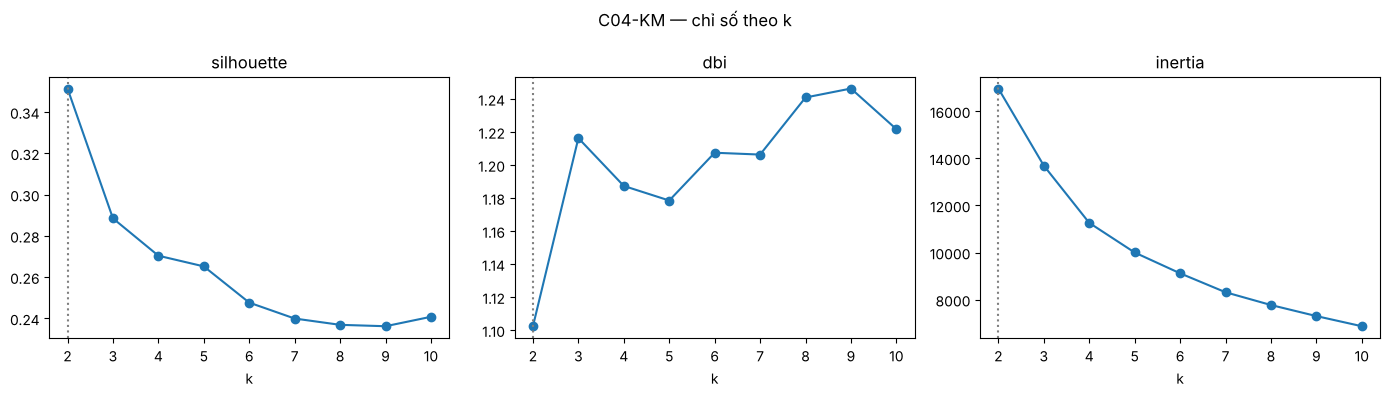

,k,silhouette,dbi,chi,inertia,min_cluster
0,2,0.3513,1.1024,2932.3109,16961.0570,2152
1,3,0.2884,1.2162,2333.1302,13688.5176,1184
2,4,0.2703,1.1873,2201.6903,11258.5873,858
3,5,0.2652,1.1785,1994.5043,10000.5363,666
4,6,0.2476,1.2074,1833.5060,9117.2214,307
5,7,0.2399,1.2063,1744.8306,8313.5941,373
6,8,0.2369,1.2408,1642.7317,7770.8806,239
7,9,0.2362,1.2463,1564.1413,7301.5256,141
8,10,0.2408,1.2217,1507.2464,6870.7537,119


In [5]:
rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=N_INIT, random_state=RANDOM_STATE).fit(Z)
    sizes = np.bincount(km.labels_, minlength=k)
    rows.append({"k": k, "silhouette": silhouette_score(Z, km.labels_), "dbi": davies_bouldin_score(Z, km.labels_),
                 "chi": calinski_harabasz_score(Z, km.labels_), "inertia": km.inertia_, "min_cluster": int(sizes.min())})
res = pd.DataFrame(rows)
best = res.loc[res["silhouette"].idxmax()]
print(f"Chọn k={int(best['k'])}: Silhouette={best['silhouette']:.4f}, DBI={best['dbi']:.4f}, CHI={best['chi']:.1f}, cụm nhỏ nhất={int(best['min_cluster'])}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["silhouette", "dbi", "inertia"]):
    ax.plot(res["k"], res[col], marker="o"); ax.axvline(int(best["k"]), color="gray", ls=":")
    ax.set_xlabel("k"); ax.set_title(col)
plt.suptitle("C04-KM — chỉ số theo k"); plt.tight_layout()
plt.savefig(FIG / "kmeans_metrics_by_k.png", dpi=150); plt.show()
res.round(4)

**Nhận xét:** Silhouette cao nhất ở k=2 (0.3513); DBI 1.1024, CHI 2932.3. Cụm nhỏ nhất có 2152 khách (49.73%).

## Train mô hình cuối

In [6]:
K = int(best["k"])
model = Pipeline([("prep", Pipeline([
        ("log1p", FunctionTransformer(np.log1p, validate=True)),
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=0.9, svd_solver="full", random_state=RANDOM_STATE)),
    ])),
                  ("kmeans", KMeans(n_clusters=K, n_init=N_INIT, random_state=RANDOM_STATE))]).fit(X.values)
labels = model["kmeans"].labels_
assert np.allclose(model["prep"].transform(X.values), Z)
print("Số khách mỗi cụm:", dict(enumerate(np.bincount(labels).tolist())))
print("Silhouette:", round(silhouette_score(Z, labels), 4), "| DBI:", round(davies_bouldin_score(Z, labels), 4))

Số khách mỗi cụm: {0: 2175, 1: 2152}
Silhouette: 0.3513 | DBI: 1.1024


## Hồ sơ cụm (trung vị trên thang gốc)

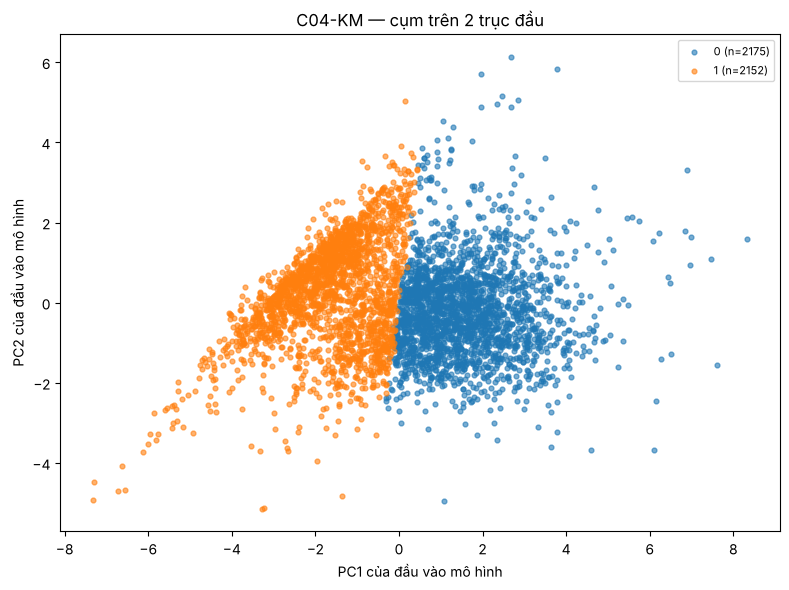

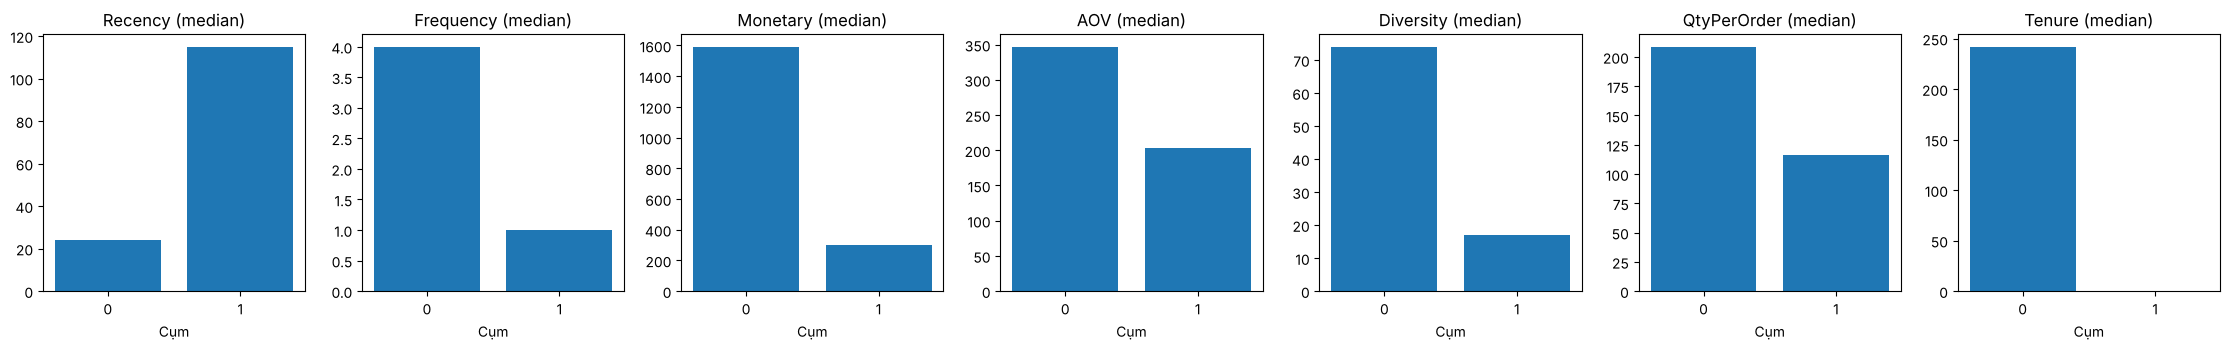

,customers,Recency,Frequency,Monetary,AOV,Diversity,QtyPerOrder,Tenure,customer_share_pct,Monetary_share_pct
cluster,,,,,,,,,,
0,2175,24.0,4.0,1592.1,347.0,74.0,208.7,241.9,50.3,91.2
1,2152,115.0,1.0,300.9,203.3,17.0,116.0,0.0,49.7,8.8


In [ ]:
agg = {f: (f, "median") for f in FEATURES}
prof = X.assign(cluster=labels).groupby("cluster").agg(customers=("Monetary", "size"), Monetary_sum=("Monetary", "sum"), **agg)
prof["customer_share_pct"] = (100 * prof["customers"] / len(X)).round(2)
prof["Monetary_share_pct"] = (100 * prof["Monetary_sum"] / prof["Monetary_sum"].sum()).round(2)
prof = prof.drop(columns="Monetary_sum").round(1)

coords = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Z) if Z.shape[1] > 2 else Z
fig, ax = plt.subplots(figsize=(8, 6))
for c in sorted(np.unique(labels)):
    m = labels == c
    ax.scatter(coords[m, 0], coords[m, 1], s=12, alpha=0.6, marker="x" if c == -1 else "o", label=f"{c} (n={m.sum()})")
ax.set_xlabel("PC1 của đầu vào mô hình"); ax.set_ylabel("PC2 của đầu vào mô hình"); ax.legend(fontsize=8)
ax.set_title("C04-KM — cụm trên 2 trục đầu")
plt.tight_layout(); plt.savefig(FIG / "kmeans_clusters_pca.png", dpi=150); plt.show()


fig, axes = plt.subplots(1, len(FEATURES), figsize=(3.2 * len(FEATURES), 3.6))
for ax, f in zip(axes, FEATURES):
    ax.bar(prof.index.astype(str), prof[f]); ax.set_title(f + " (median)"); ax.set_xlabel("Cụm")
plt.tight_layout(); plt.savefig(FIG / "feature_comparison.png", dpi=150); plt.show()
prof

**Nhận xét:** Cụm 0 có Monetary trung vị cao nhất (1,592), gồm 2175 khách (50.3%) nhưng chiếm 91.2% tổng Monetary. Cụm 0 đông nhất (50.3% khách, Recency trung vị 24 ngày).

## Đối chiếu với C01 (cùng tham số model)

In [ ]:

prep_parent = Pipeline([
    ("log1p", FunctionTransformer(np.log1p, validate=True)),
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.9, svd_solver="full", random_state=RANDOM_STATE)),
])
Zp = prep_parent.fit_transform(X[FEATURES_PARENT].values)
lp = KMeans(n_clusters=K, n_init=N_INIT, random_state=RANDOM_STATE).fit_predict(Zp)
ari_parent = adjusted_rand_score(labels, lp)
same_dims = Zp.shape[1] == Z.shape[1] and FEATURES_PARENT == FEATURES
same_geometry = same_dims and np.allclose(np.linalg.norm(Z[:300, None] - Z[None, :300], axis=2),
                                          np.linalg.norm(Zp[:300, None] - Zp[None, :300], axis=2), atol=1e-8)
print(f"C04: {Z.shape[1]} chiều | C01: {Zp.shape[1]} chiều")
print(f"ARI giữa nhãn C04 và nhãn C01 (cùng tham số): {ari_parent:.4f}")
print("Cùng hình học khoảng cách:", same_geometry)

C04: 4 chiều | C01: 3 chiều
ARI giữa nhãn C04 và nhãn C01 (cùng tham số): 0.7026
Cùng hình học khoảng cách: False


**Nhận xét:** ARI giữa C04 và C01 (cùng tham số) = 0.7026; số chiều đầu vào 4 so với 3. Nhãn khác một phần: việc thêm feature có tác động vừa phải.

## Lưu kết quả

In [9]:
res.to_csv(OUT / "kmeans_c04_metrics_by_k.csv", index=False)
pd.DataFrame({"CustomerID": df["CustomerID"], "cluster": labels}).to_csv(OUT / "kmeans_c04_labels.csv", index=False)
joblib.dump(model, "kmeans_c04_model.pkl")
params = {"experiment": "C04-KM", "features": FEATURES, "feature_sources": {k: v for v, k in RENAME.items() if k in FEATURES}, "transform": 'log1p',
          "scaler": "StandardScaler", "pca": 0.9,
          "n_components": int(Z.shape[1]), "n_customers": int(len(X)),
          "pca_variance_kept": float(model["prep"]["pca"].explained_variance_ratio_.sum()),
          "k": K, "silhouette": float(silhouette_score(Z, labels)), "dbi": float(davies_bouldin_score(Z, labels)),
          "chi": float(calinski_harabasz_score(Z, labels)), "inertia": float(model["kmeans"].inertia_),
          "n_init": N_INIT,
          "ari_vs_parent_fixed_params": {"parent": "C01", "ari": float(ari_parent)}}
json.dump(params, open(OUT / "kmeans_c04_params.json", "w", encoding="utf8"), ensure_ascii=False, indent=2)
print("Đã lưu:", sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['kmeans_c04_labels.csv', 'kmeans_c04_metrics_by_k.csv', 'kmeans_c04_params.json']


**Kết luận C04-KM:** K-Means chọn k=2 (Silhouette 0.3513) trên 4 chiều đầu vào. ARI với C01 (cùng tham số) = 0.7026. Silhouette giữa các cấu hình khác không gian đầu vào (số chiều, scaler) không so sánh trực tiếp được; dùng ARI và hồ sơ cụm trên thang gốc để so sánh.